# Hierarchical Bayes for projects

This is a reference notebook for the final projects. It is not graded and has no exercises.

Each section adds one idea. Read the sections in order, or jump to the one that matches your problem using the table below. Run the cells from the top. Every section is short, and each one ends with a "Try it on your project" box.

Rules used throughout.

- Every data set is either a real file from the course data folder or simulated. Simulated data and made-up numbers are labeled as such.
- Every number quoted in the text is printed by the code above it.
- All random seeds are fixed, so you get the same numbers when you rerun.
- The notebook runs on a laptop CPU in about a minute. The only extra package is `numpyro`, and the first cell installs it if it is missing.

| Problem type | Sections |
|---|---|
| A stored baseline updated with a new noisy measurement | 1, 5, 8 |
| A rate for many groups with few trials each (decks, lifters) | 3, 4, 7 |
| Many groups with a continuous outcome (watch models on log price) | 5 |
| Regression with an upper-quantile decision | 2, 6 |
| A logistic model with a prior | 7 |
| Counts and a staffing quantile | 2 |
| Rare events, possibly none observed in a group | 3 |
| Scoring any of the above honestly | 9 |

Quantile regression and gradient boosted classifiers (GBC) are covered in a separate notebook, [quantiles-gbc.ipynb](quantiles-gbc.ipynb).

In [1]:
import warnings

warnings.filterwarnings("ignore", message="IProgress")
try:
    import numpyro
except ImportError:
    get_ipython().run_line_magic("pip", "install -q numpyro")
    import numpyro

from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import betaln, expit

DATA = Path("data")
DATA.mkdir(exist_ok=True)
BASE = "https://vsokolov.org/courses/files/600/data"
for name in ("EfronMorrisBB.txt", "SaratogaHouses.csv"):
    path = DATA / name
    if not path.exists():
        urlretrieve(f"{BASE}/{name}", path)

plt.rcParams.update({"figure.figsize": (6, 3.6), "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})
print("numpyro", numpyro.__version__)

numpyro 0.22.0


## 1. A normal prior plus data, with the prior fixed

**Idea.** A prior is a number you write down before you see the data. Data move it, and the prior pulls the data back. The size of the pull is one formula.

**Data.** The 2014 Chicago Bears had played 9 games. Here are the game margins in points (own score minus opponent score, so negative is a loss): -3, 8, 8, -21, -7, 14, -13, -28, -41. The next game had a betting line of -3.5. A line is the market's guess of the margin.

**Notation.**

- $y_i$ is the margin of game $i$, for $i = 1, \dots, n$ with $n = 9$.
- $\mu$ is the true average margin of this team. It is unknown.
- $\sigma$ is the standard deviation of one margin. We treat it as known and set it to the sample standard deviation $s$.
- $\bar y$ is the sample mean of the margins.
- $\mu_0$ is the prior mean of $\mu$, and $\tau$ is the prior standard deviation of $\mu$. Here $\mu_0 = 0$ (an average team) and $\tau = 4$ points.

**Model.** $\bar y \mid \mu \sim N(\mu, \sigma^2/n)$ and $\mu \sim N(\mu_0, \tau^2)$.

**Posterior.** The posterior of $\mu$ is normal with mean $\mu_n = \mu_0 + B(\bar y - \mu_0)$ and variance $\sigma_n^2 = \left(1/\tau^2 + n/\sigma^2\right)^{-1}$. The shrinkage factor is $B = \tau^2 / (\tau^2 + \sigma^2/n)$. It is the weight on the data. The weight on the prior is $1 - B$.

**Market-implied $\tau$.** With $\mu_0 = 0$, the posterior mean equals the line when $B = \text{line}/\bar y$. Solving $B = \tau^2/(\tau^2 + \sigma^2/n)$ for $\tau$ gives $\tau^2 = \frac{B}{1-B}\,\sigma^2/n$.

n = 9, mean margin = -9.22, sd of one margin = 18.34
shrinkage factor B = 0.30, posterior mean = -2.76, posterior sd = 3.35
market line = -3.5, weight on data implied by the line = 0.38
market-implied tau = 4.78

How the answer depends on the fixed tau:
  tau =   1   B = 0.03   posterior mean =  -0.24
  tau =   2   B = 0.10   posterior mean =  -0.89
  tau =   4   B = 0.30   posterior mean =  -2.76
  tau =   8   B = 0.63   posterior mean =  -5.82
  tau =  16   B = 0.87   posterior mean =  -8.05
  tau = 100   B = 1.00   posterior mean =  -9.19


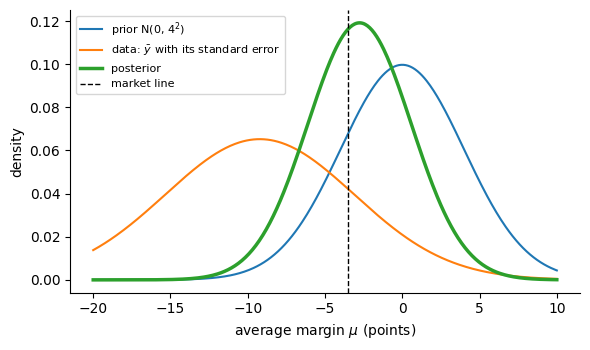

In [2]:
margins = np.array([-3, 8, 8, -21, -7, 14, -13, -28, -41])
n = len(margins)
ybar = margins.mean()
s = margins.std(ddof=1)          # plays the role of sigma
mu0, tau = 0.0, 4.0
se2 = s**2 / n                   # variance of the sample mean

B = tau**2 / (tau**2 + se2)      # shrinkage factor: the weight on the data
mu_n = mu0 + B * (ybar - mu0)    # posterior mean
var_n = 1 / (1 / tau**2 + n / s**2)

line = -3.5
B_mkt = line / ybar              # weight that would reproduce the line
tau_mkt = np.sqrt(B_mkt / (1 - B_mkt) * se2)

print(f"n = {n}, mean margin = {ybar:.2f}, sd of one margin = {s:.2f}")
print(f"shrinkage factor B = {B:.2f}, posterior mean = {mu_n:.2f}, posterior sd = {np.sqrt(var_n):.2f}")
print(f"market line = {line}, weight on data implied by the line = {B_mkt:.2f}")
print(f"market-implied tau = {tau_mkt:.2f}")

print("\nHow the answer depends on the fixed tau:")
for t in (1, 2, 4, 8, 16, 100):
    Bt = t**2 / (t**2 + se2)
    print(f"  tau = {t:3d}   B = {Bt:.2f}   posterior mean = {Bt * ybar:6.2f}")

grid = np.linspace(-20, 10, 400)
plt.figure()
plt.plot(grid, stats.norm.pdf(grid, mu0, tau), label=f"prior N(0, {tau:.0f}$^2$)")
plt.plot(grid, stats.norm.pdf(grid, ybar, np.sqrt(se2)), label="data: $\\bar y$ with its standard error")
plt.plot(grid, stats.norm.pdf(grid, mu_n, np.sqrt(var_n)), lw=2.5, label="posterior")
plt.axvline(line, color="black", ls="--", lw=1, label="market line")
plt.xlabel("average margin $\\mu$ (points)")
plt.ylabel("density")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Reading.**

- The mean margin is -9.22 points over 9 games. The sample standard deviation of one margin is 18.34.
- The shrinkage factor is 0.30. The data get a weight of 30% and the prior gets the rest.
- The posterior mean is -2.76. The market line is -3.5. The raw mean of -9.22 is much further from the line than the posterior mean is.
- The line implies a weight on the data of 0.38. That corresponds to a prior standard deviation of 4.8 points, close to the 4 we assumed.
- The table shows that the answer depends on $\tau$. A small $\tau$ trusts the prior. A large $\tau$ trusts the data.

**Not yet hierarchical.** Here $\tau$ is fixed by us. We chose it. This is one normal update with a fixed prior. The book calls this example hierarchical, but nothing in the data tells us about $\tau$ yet. A model is hierarchical when $\tau$ is also unknown and the data help to learn it. Section 5 does that, and the difference is the point of Section 5.

**Try it on your project.** Write down your baseline as a prior mean $\mu_0$ and a prior standard deviation $\tau$. Say in one sentence where $\tau$ comes from. Compute $B$ and the posterior mean. Then compute the $\tau$ implied by any market or reference number you have, and compare it with your $\tau$.

## 2. From a posterior predictive to a decision

**Idea.** A decision needs a forecast of the next observation, not only of $\mu$. The forecast has two sources of spread: the noise of one observation, and our remaining doubt about $\mu$.

**Normal case.** Let $y_{n+1}$ be the next margin. Given $\mu$ it is $N(\mu, \sigma^2)$. Averaging over the posterior of $\mu$ gives the posterior predictive

$$y_{n+1} \mid y_1, \dots, y_n \sim N(\mu_n, \; \sigma_n^2 + \sigma^2).$$

Here $\mu_n$ and $\sigma_n^2$ are the posterior mean and variance from Section 1.

**From the forecast to a number.** Suppose we must commit to a number $a$ before we see $y_{n+1}$. If $y_{n+1}$ ends above $a$ we lose $c_{\text{under}}$ per unit. If it ends below $a$ we lose $c_{\text{over}}$ per unit. The best $a$ is the quantile of the predictive at level

$$\gamma = \frac{c_{\text{under}}}{c_{\text{under}} + c_{\text{over}}}.$$

We call $\gamma$ the critical ratio. It is not related to the prior standard deviation $\tau$. The costs below are made up.

In [3]:
pred_mean = mu_n
pred_sd = np.sqrt(var_n + s**2)

c_under, c_over = 3.0, 1.0       # made-up costs per point
gamma = c_under / (c_under + c_over)
a_star = stats.norm.ppf(gamma, pred_mean, pred_sd)
a_plug = stats.norm.ppf(gamma, pred_mean, s)     # ignores the doubt about mu

# brute-force check: the expected loss is smallest at the quantile
rng = np.random.default_rng(2)
draws = rng.normal(pred_mean, pred_sd, 200_000)
cand = np.linspace(-30, 30, 601)
exp_loss = np.array([np.mean(np.where(draws > a, c_under * (draws - a), c_over * (a - draws))) for a in cand])
a_grid = cand[exp_loss.argmin()]

print(f"predictive: mean {pred_mean:.2f}, sd {pred_sd:.2f}  (sigma alone: {s:.2f})")
print(f"critical ratio gamma = {c_under:.0f}/({c_under:.0f}+{c_over:.0f}) = {gamma:.2f}")
print(f"best number a = {a_star:.2f}   (without parameter doubt: {a_plug:.2f})")
print(f"brute-force minimiser of expected loss on a grid: {a_grid:.2f}")

predictive: mean -2.76, sd 18.65  (sigma alone: 18.34)
critical ratio gamma = 3/(3+1) = 0.75
best number a = 9.81   (without parameter doubt: 9.61)
brute-force minimiser of expected loss on a grid: 9.80


**Reading.**

- The predictive has mean -2.76 and standard deviation 18.65. The standard deviation of one margin alone is 18.34, so the doubt about $\mu$ adds only a little.
- The costs give $\gamma =$ 0.75. Under-shooting is three times as costly as over-shooting, so we commit to a high number, the 75% quantile.
- The best number is 9.81. A grid search over the expected loss gives 9.80. They agree, which confirms that the quantile is the answer.
- If you left out the doubt about $\mu$, you would get 9.61. The gap is small here because $n$ is not tiny and $\tau$ is small.

**Counts.** For counts, the same idea uses the Poisson-Gamma model. Let $y_t$ be the count on day $t$ with $y_t \sim \text{Poisson}(\lambda)$, where $\lambda$ is the daily rate. Let the prior be $\lambda \sim \text{Gamma}(a_0, A_0)$ with shape $a_0$ and rate $A_0$, so the prior mean is $a_0/A_0$. After $n$ days with total count $N$, the posterior is Gamma with shape $a_n = a_0 + N$ and rate $A_n = A_0 + n$. The predictive count for the next day is negative binomial with mean $a_n/A_n$. It is wider than a Poisson with the same mean.

The next code uses a **simulated** series of 5 daily counts, generated from a Poisson rate of 8. The prior is made up: it expects 6 per day and is weak, with shape 3 and rate 0.5. Staffing costs are made up too: one missing person costs 9, one extra person costs 1.

In [4]:
rng = np.random.default_rng(3)
counts = rng.poisson(8.0, size=5)            # simulated daily counts
a0, A0 = 3.0, 0.5                             # made-up prior Gamma(shape 3, rate 0.5), mean 6
a_n, A_n = a0 + counts.sum(), A0 + len(counts)
rate_post = a_n / A_n

nb = stats.nbinom(a_n, A_n / (A_n + 1))       # negative binomial predictive for the next day
c_short, c_extra = 9.0, 1.0                   # made-up staffing costs
gamma_c = c_short / (c_short + c_extra)

k_nb = int(nb.ppf(gamma_c))                              # smallest k with cdf >= gamma
k_mle = int(stats.poisson.ppf(gamma_c, counts.mean()))   # plug in the sample mean
k_plug = int(stats.poisson.ppf(gamma_c, rate_post))      # plug in the posterior mean

# check by simulation: draw the rate, then the count, and price each staffing level
lam = rng.gamma(a_n, 1 / A_n, 300_000)
y_next = rng.poisson(lam)
def cost(k):
    return np.mean(np.where(y_next > k, c_short * (y_next - k), c_extra * (k - y_next)))
k_best = min(range(0, 31), key=cost)

print("simulated counts:", counts.tolist(), " mean", counts.mean())
print(f"prior mean {a0 / A0:.1f}; posterior Gamma({a_n:.0f}, {A_n:.0f}), mean {rate_post:.2f}")
print(f"predictive mean {nb.mean():.2f}, sd {nb.std():.2f}  (Poisson with the same mean: sd {np.sqrt(rate_post):.2f})")
print(f"gamma = {gamma_c:.2f}")
print(f"staffing level from the negative binomial: {k_nb}")
print(f"staffing level from Poisson at the sample mean: {k_mle}; at the posterior mean: {k_plug}")
print(f"staffing level with the smallest simulated cost: {k_best}")
print(f"P(count <= {k_plug}) under the negative binomial: {nb.cdf(k_plug):.2f}")

simulated counts: [6, 9, 3, 9, 8]  mean 7.0
prior mean 6.0; posterior Gamma(38, 6), mean 6.91
predictive mean 6.91, sd 2.86  (Poisson with the same mean: sd 2.63)
gamma = 0.90
staffing level from the negative binomial: 11
staffing level from Poisson at the sample mean: 10; at the posterior mean: 10
staffing level with the smallest simulated cost: 11
P(count <= 10) under the negative binomial: 0.89


**Reading.**

- The 5 simulated counts have mean 7.0. The posterior mean rate is 6.91, between the prior mean 6.0 and the data mean.
- The predictive standard deviation is 2.86, against 2.63 for a Poisson with the same mean. The extra width is the doubt about $\lambda$.
- The costs give $\gamma =$ 0.90. The staffing level is the smallest $k$ whose predictive probability of $y \le k$ is at least $\gamma$. The negative binomial gives 11. The plug-in Poisson gives 10 at the sample mean and 10 at the posterior mean.
- A simulation of the expected cost picks 11. It matches the negative binomial quantile.
- A staffing level of 10 (the plug-in choice) covers the next day with probability 89.0% under the negative binomial, against a target of 90%. Ignoring the doubt about $\lambda$ leaves you slightly short. The gap grows when there are fewer days of data.

**Try it on your project.** State the two costs and compute $\gamma$. Take the $\gamma$ quantile of the predictive, not of the plug-in fit. If your outcome is a count, use the negative binomial. If it is continuous, use the normal or Student t predictive (Section 6). Report the cost you pay with the quantile and with the median.

## 3. Rates for a few groups, rare events, and partial pooling

**Idea.** A rate from a small group is noisy. A rate from zero events is not zero. A shared prior learned from all groups gives each group a better estimate.

**Data.** Novick and Grizzle (1965) compared four operations for duodenal ulcers on 100 patients each. The outcome was Excellent, Fair, or Death. The deaths were 7, 1, 1, and 3 for treatments A to D.

| Treatment | Excellent | Fair | Death | Total |
|---|---|---|---|---|
| A | 76 | 17 | 7 | 100 |
| B | 89 | 10 | 1 | 100 |
| C | 86 | 13 | 1 | 100 |
| D | 88 | 9 | 3 | 100 |

**Notation.** $p_j$ is the true death rate under treatment $j$. $y_j$ is the number of deaths and $n_j = 100$ the number of patients. With a flat Beta(1, 1) prior, the posterior is $p_j \mid y_j \sim \text{Beta}(1 + y_j, \; 1 + n_j - y_j)$.

**Part A. Independent posteriors.** Each treatment gets its own posterior. We ask for the probability that A is worse than B by drawing from both posteriors and counting how often $p_A > p_B$.

In [5]:
arms = ["A", "B", "C", "D"]
deaths = np.array([7, 1, 1, 3])
n_pat = np.array([100, 100, 100, 100])
rng = np.random.default_rng(3)
draws_p = {a: rng.beta(1 + d, 1 + m - d, 400_000) for a, d, m in zip(arms, deaths, n_pat)}

p_AB = np.mean(draws_p["A"] > draws_p["B"])
p_AC = np.mean(draws_p["A"] > draws_p["C"])
p_AD = np.mean(draws_p["A"] > draws_p["D"])

print("treatment  deaths  posterior mean  95% interval")
for a, d, m in zip(arms, deaths, n_pat):
    lo, hi = stats.beta.ppf([0.025, 0.975], 1 + d, 1 + m - d)
    print(f"   {a}        {d}        {(1 + d) / (2 + m):.3f}        ({lo:.3f}, {hi:.3f})")
print(f"P(p_A > p_B) = {p_AB:.3f}   P(p_A > p_C) = {p_AC:.3f}   P(p_A > p_D) = {p_AD:.3f}")

table = np.array([[76, 17, 7], [89, 10, 1], [86, 13, 1], [88, 9, 3]])
chi2, p_chi, dof, expected = stats.chi2_contingency(table)
print(f"chi-square on the full table: statistic {chi2:.2f}, df {dof}, p = {p_chi:.3f}")
print(f"expected deaths per treatment under equal rates: {expected[0, 2]:.0f}")

treatment  deaths  posterior mean  95% interval
   A        7        0.078        (0.035, 0.138)
   B        1        0.020        (0.002, 0.054)
   C        1        0.020        (0.002, 0.054)
   D        3        0.039        (0.011, 0.084)
P(p_A > p_B) = 0.982   P(p_A > p_C) = 0.983   P(p_A > p_D) = 0.893
chi-square on the full table: statistic 12.42, df 6, p = 0.053
expected deaths per treatment under equal rates: 3


**Reading.**

- The posterior probability that A has a higher death rate than B is 0.982. For C it is 0.983, and for D it is 0.893.
- The chi-square test on the full table gives a statistic of 12.42 on 6 degrees of freedom and $p =$ 0.053. That does not reject equal rates at the 5% level.
- Expected deaths under equal rates are only 3 per treatment, so the chi-square approximation is rough here.
- The two answers do not contradict each other. The test answers whether all four rates could be equal. The posterior answers how likely it is that A is worse than B. Those are different questions.

**Part B. Rare events.** Suppose a group has zero events in $n$ trials. The estimate $y/n$ is exactly 0, and it claims the event is impossible. The posterior does not. With a Beta(1, 1) prior, zero events in $n = 100$ trials give Beta(1, 101).

In [6]:
n_trials = 100
a_post, b_post = 1, 1 + n_trials                      # Beta(1, 101) after 0 events in 100
post_mean_0 = a_post / (a_post + b_post)
upper95 = stats.beta.ppf(0.95, a_post, b_post)
# P(at least one event in the next 100 trials) = 1 - E[(1 - p)^100]
p_next100 = 1 - np.exp(betaln(a_post, b_post + 100) - betaln(a_post, b_post))
rng = np.random.default_rng(42)
p_next100_mc = np.mean(1 - (1 - rng.beta(a_post, b_post, 200_000)) ** 100)

print(f"maximum likelihood estimate: {0 / n_trials:.3f}")
print(f"posterior mean: {post_mean_0:.4f}   95% upper bound: {upper95:.3f}   rule of three, 3/n: {3 / n_trials:.3f}")
print(f"P(at least one event in the next 100 trials): exact {p_next100:.3f}, simulated {p_next100_mc:.3f}")

maximum likelihood estimate: 0.000
posterior mean: 0.0098   95% upper bound: 0.029   rule of three, 3/n: 0.030
P(at least one event in the next 100 trials): exact 0.498, simulated 0.497


**Reading.**

- The maximum likelihood estimate is 0. The posterior mean is 0.0098, and the 95% upper bound for the rate is 0.029. The rule of three says the 95% upper bound is about $3/n =$ 0.030, close to the posterior bound.
- The chance of at least one event in the next 100 trials is 0.498 (exact) and 0.497 (simulation), about one half. This is the black swan example from the book. After 100 white swans, a black swan somewhere in the next 100 is still about as likely as not.

**Part C. Partial pooling.** The independent posteriors treat the four rates as unrelated. Partial pooling says that the four rates come from one shared Beta distribution, $p_j \sim \text{Beta}(a, b)$. We write the shared prior with two numbers.

- $m = a/(a+b)$ is the mean death rate across treatments.
- $k = a + b$ is the concentration. A large $k$ means the rates are close to each other. A small $k$ means they differ a lot.

The data enter through the beta-binomial marginal likelihood. For group $j$ it is $\text{B}(a + y_j, \, b + n_j - y_j) / \text{B}(a, b)$, up to a constant that does not depend on $a$ or $b$. Here $\text{B}$ is the beta function. We evaluate the product over groups on a grid of $(m, k)$ with a flat prior on $m$ and a flat prior on $\log k$. Given $(a, b)$, group $j$ has posterior mean $(a + y_j)/(a + b + n_j)$. We average this over the grid, weighted by the posterior of $(m, k)$.

The weight on the group's own rate is $n_j/(n_j + k)$. A small group has a small weight, and its estimate moves more.

In [7]:
def pool_grid(y, n, n_m=400, k_min=1.0, k_max=5000.0, n_k=150):
    """Beta-binomial partial pooling on a grid over the mean m and concentration k = a + b.
    The prior is flat in m and flat in log k. Returns posterior means per group and a summary of (m, k)."""
    y, n = np.asarray(y, float), np.asarray(n, float)
    m_grid = np.linspace(0.0005, 0.9995, n_m)
    k_grid = np.exp(np.linspace(np.log(k_min), np.log(k_max), n_k))
    M, K = np.meshgrid(m_grid, k_grid, indexing="ij")
    a, b = M * K, (1 - M) * K
    loglik = sum(betaln(a + yi, b + ni - yi) - betaln(a, b) for yi, ni in zip(y, n))
    w = np.exp(loglik - loglik.max())
    w /= w.sum()
    post_mean = np.array([np.sum(w * (a + yi) / (K + ni)) for yi, ni in zip(y, n)])
    wk = np.cumsum(w.sum(axis=0))
    k_q = np.interp([0.05, 0.5, 0.95], wk, k_grid)
    return {"post_mean": post_mean, "m_mean": np.sum(w * M), "k_q": k_q, "w": w, "k_grid": k_grid}

fit_u = pool_grid(deaths, n_pat)
ind_mean = (1 + deaths) / (2 + n_pat)
raw_rate = deaths / n_pat
pooled_rate = deaths.sum() / n_pat.sum()

print(f"shared prior: mean rate {fit_u['m_mean']:.3f}; concentration k median {fit_u['k_q'][1]:.0f} (90% interval {fit_u['k_q'][0]:.0f} to {fit_u['k_q'][2]:.0f})")
print(f"all four pooled into one rate: {pooled_rate:.3f}")
print("treatment  observed  independent  partial pooling")
for i, a in enumerate(arms):
    print(f"   {a}        {raw_rate[i]:.3f}      {ind_mean[i]:.3f}        {fit_u['post_mean'][i]:.3f}")

# Made-up fifth treatment E with zero deaths in 20 patients, to show a group with no events.
y_e = np.append(deaths, 0)
n_e = np.append(n_pat, 20)
fit_e = pool_grid(y_e, n_e)
ind_e = (1 + y_e[-1]) / (2 + n_e[-1])
print(f"\nmade-up arm E: 0 deaths in 20 patients")
print(f"  observed rate 0.000; independent Beta(1,1) mean {ind_e:.3f}; partial pooling mean {fit_e['post_mean'][-1]:.3f}")
print(f"  mean rate of the other four under partial pooling: {fit_e['post_mean'][:-1].mean():.3f}")

shared prior: mean rate 0.048; concentration k median 82 (90% interval 4 to 2732)
all four pooled into one rate: 0.030
treatment  observed  independent  partial pooling
   A        0.070      0.078        0.053
   B        0.010      0.020        0.022
   C        0.010      0.020        0.022
   D        0.030      0.039        0.032



made-up arm E: 0 deaths in 20 patients
  observed rate 0.000; independent Beta(1,1) mean 0.045; partial pooling mean 0.025
  mean rate of the other four under partial pooling: 0.031


**Reading.**

- The four observed rates range from 0.01 to 0.07. The independent Beta(1, 1) means are pulled slightly toward 0.5. The partial pooling means are pulled toward the shared mean of 0.048.
- Treatment A moves from an observed 0.070 to 0.053. Treatment B moves from 0.010 to 0.022. The extremes move the most.
- The concentration $k$ is poorly known with only four groups. Its median is 82, and the 90% interval runs from 4 to 2732. Four groups cannot say much about how alike the groups are, so the amount of pooling is uncertain. Section 5 shows the same effect with eight groups.
- The made-up arm E has zero deaths in 20 patients. Its independent posterior mean is 0.045, driven by the flat prior. With partial pooling it is 0.025, close to the other arms. A group with no events borrows strength from the groups that have some.

**Try it on your project.** List your groups and, for each, the number of events and trials. Compute the independent posterior and the partially pooled estimate side by side. Look at the groups with the fewest trials first, since they move the most. If a group has zero events, report its posterior upper bound, not zero.

## 4. Many groups with unequal sample sizes: baseball

**Idea.** When groups have different numbers of trials, the shared prior shrinks the small groups the most.

**Data.** Efron and Morris took 18 baseball players in the 1970 season. For each they recorded hits in the first 45 at-bats and the batting average over the rest of the season. We score the estimates against the rest-of-season average. This notebook introduces these data. Lab 11 revisits them with the James-Stein rule.

**Notation.** For player $i$, $y_i$ is the number of hits, $n_i$ the number of at-bats, and $p_i$ the true batting ability. The model is $y_i \mid p_i \sim \text{Bin}(n_i, p_i)$ and $p_i \sim \text{Beta}(a, b)$, the same as in Section 3. The posterior mean of $p_i$ is $(a + y_i)/(a + b + n_i)$.

The book also writes the spread of the shared prior as $\phi = 1/(a + b + 1)$. A small $\phi$ means the players are alike.

In [8]:
bb = pd.read_csv(DATA / "EfronMorrisBB.txt", sep="\t")
bb["name"] = bb.FirstName + " " + bb.LastName
y_h = bb.Hits.to_numpy()
n_h = bb.AtBats.to_numpy()
rest = bb.RemainingAverage.to_numpy()

fit_b = pool_grid(y_h, n_h)
raw_h = y_h / n_h
eb_h = fit_b["post_mean"]
grand = y_h.sum() / n_h.sum()

mse_raw = np.mean((raw_h - rest) ** 2)
mse_eb = np.mean((eb_h - rest) ** 2)
mse_grand = np.mean((grand - rest) ** 2)
k_b = fit_b["k_q"][1]

print(f"players: {len(bb)}; at-bats per player: min {n_h.min()}, max {n_h.max()}")
print(f"shared prior: mean {fit_b['m_mean']:.3f}; concentration k median {k_b:.0f} (90% interval {fit_b['k_q'][0]:.0f} to {fit_b['k_q'][2]:.0f})")
print(f"weight on own average, n/(n+k) at k = {k_b:.0f}: {45 / (45 + k_b):.2f}")
print("mean squared error against the rest of the season")
print(f"  raw early averages:  {mse_raw:.5f}")
print(f"  beta-binomial Bayes: {mse_eb:.5f}")
print(f"  grand mean for all:  {mse_grand:.5f}")

players: 18; at-bats per player: min 45, max 45
shared prior: mean 0.266; concentration k median 539 (90% interval 58 to 3987)
weight on own average, n/(n+k) at k = 539: 0.08
mean squared error against the rest of the season
  raw early averages:  0.00476
  beta-binomial Bayes: 0.00147
  grand mean for all:  0.00158


**Reading.**

- Every player has 45 at-bats, so the sample sizes are equal. Then every player shrinks by the same fraction, and the small-sample effect cannot show. We show it next with a simulation.
- The shared prior has mean 0.266 and a concentration $k$ with median 539. The weight on a player's own average is $45/(45+k) =$ 0.08.
- Against the rest of the season, the raw averages have a mean squared error of 0.00476. The Bayes estimates have 0.00147, which is about 3.2 times smaller. Using the grand mean for everyone gives 0.00158.
- The rest-of-season average is itself a noisy measure of ability. This is why even the grand mean scores well.

**Simulated unequal sample sizes.** The code below simulates 40 players. It is labeled **simulated**: the true abilities come from a Beta distribution with mean 0.27 and concentration 80, and the number of at-bats ranges from about 5 to 600. We fit the shared prior without using the truth, and then compare with the true abilities, which are known in a simulation.

simulated: true mean 0.27, true k 80; fitted mean 0.272, k median 83 (90% interval 41 to 171)
         players  mean shift  rmse raw  rmse bayes
size                                              
5-20        14.0       0.097     0.150       0.055
21-60       10.0       0.046     0.062       0.022
61-200       6.0       0.021     0.033       0.023
201-600     10.0       0.010     0.026       0.026
overall rmse against the true abilities: raw 0.096, bayes 0.038


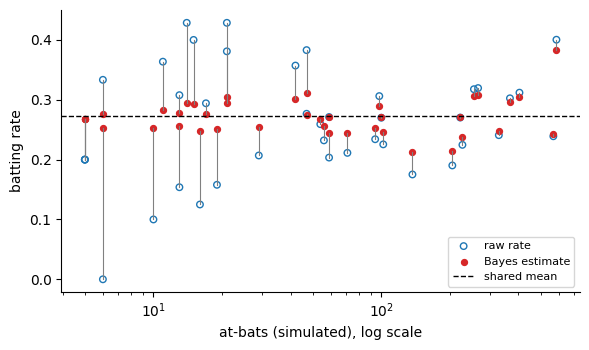


the book's Jeter table lists 17 pitchers with 441 at-bats and 146 hits in total, against a quoted season total of 6530 at-bats
P(1 hit or fewer in 19 at-bats | p = 0.3) = 0.010


In [9]:
rng = np.random.default_rng(7)
G_sim = 40
n_sim = np.round(np.exp(rng.uniform(np.log(5), np.log(600), G_sim))).astype(int)   # simulated at-bats
m_true, k_true = 0.27, 80.0                                                          # simulated truth
p_sim = rng.beta(m_true * k_true, (1 - m_true) * k_true, G_sim)
y_sim = rng.binomial(n_sim, p_sim)

fit_s = pool_grid(y_sim, n_sim)
raw_s = y_sim / n_sim
eb_s = fit_s["post_mean"]
k_s = fit_s["k_q"][1]

df = pd.DataFrame({"n": n_sim, "truth": p_sim, "raw": raw_s, "bayes": eb_s})
df["shift"] = np.abs(df.bayes - df.raw)
df["size"] = pd.cut(df.n, [0, 20, 60, 200, 1000], labels=["5-20", "21-60", "61-200", "201-600"])
by = df.groupby("size", observed=True).apply(
    lambda g: pd.Series({"players": len(g), "mean shift": g["shift"].mean(),
                         "rmse raw": np.sqrt(np.mean((g.raw - g.truth) ** 2)),
                         "rmse bayes": np.sqrt(np.mean((g.bayes - g.truth) ** 2))}),
    include_groups=False)
print(f"simulated: true mean {m_true}, true k {k_true:.0f}; fitted mean {fit_s['m_mean']:.3f}, k median {k_s:.0f} (90% interval {fit_s['k_q'][0]:.0f} to {fit_s['k_q'][2]:.0f})")
print(by.round(3).to_string())
print(f"overall rmse against the true abilities: raw {np.sqrt(np.mean((raw_s - p_sim) ** 2)):.3f}, bayes {np.sqrt(np.mean((eb_s - p_sim) ** 2)):.3f}")

plt.figure()
for i in range(G_sim):
    plt.plot([n_sim[i], n_sim[i]], [raw_s[i], eb_s[i]], color="gray", lw=0.8)
plt.scatter(n_sim, raw_s, facecolors="none", edgecolors="C0", s=22, label="raw rate")
plt.scatter(n_sim, eb_s, color="C3", s=18, label="Bayes estimate")
plt.axhline(fit_s["m_mean"], color="black", ls="--", lw=1, label="shared mean")
plt.xscale("log")
plt.xlabel("at-bats (simulated), log scale")
plt.ylabel("batting rate")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Stern's Jeter and Lofton story: quoted from the book, not reproduced here.
pitchers = {"Mendoza": (6, 5), "Nomo": (20, 12), "Burnett": (5, 3), "Milton": (28, 14), "Cone": (8, 4), "Lopez": (45, 21),
            "Escobar": (39, 16), "Wettland": (5, 2), "Wakefield": (81, 26), "Martinez": (83, 21), "Benson": (8, 2),
            "Hudson": (24, 6), "Smoltz": (5, 1), "Garcia": (25, 5), "Radke": (41, 8), "Kolb": (5, 0), "Julio": (13, 0)}
ab_tab = sum(v[0] for v in pitchers.values())
h_tab = sum(v[1] for v in pitchers.values())
p_lofton = stats.binom.cdf(1, 19, 0.3)
print(f"\nthe book's Jeter table lists {len(pitchers)} pitchers with {ab_tab} at-bats and {h_tab} hits in total, against a quoted season total of 6530 at-bats")
print(f"P(1 hit or fewer in 19 at-bats | p = 0.3) = {p_lofton:.3f}")

**Reading.**

- The fitted concentration has median 83 against a true value of 80, and the fitted mean is 0.272 against 0.27.
- In the table, the mean shift from the raw rate to the Bayes estimate is 0.097 for players with 5 to 20 at-bats. It is 0.010 for players with 201 to 600 at-bats. Small samples shrink most.
- For the smallest players, the root mean squared error against the true ability drops from 0.150 to 0.055. For the largest players the two errors are 0.026 and 0.026, almost the same.
- In the plot, the vertical gray lines are longest on the left, where there are few at-bats.

**A story from the book, with a caveat.** Stern (2007) fitted this beta-binomial model to Derek Jeter's 2006 season, with pitchers as the groups, and reported $\hat\phi = 0.002$. That is almost no variation across pitchers, so his estimates sit close to his season average. For Kenny Lofton the fitted value was $\hat\phi = 0.008$, four times larger. On Aug 29, 2006 Lofton was rested against the pitcher Milton, against whom he was 1 for 19. If his true average were 0.3, one hit or fewer in 19 at-bats has probability 0.010. The model, which also accounts for the many other pitchers, still put his estimate against Milton at 0.265, below the 0.273 of the replacement hitter. We quote this as a story. We do not reproduce it. The book's Jeter table lists only 17 pitchers with 441 at-bats, against a season total of 6,530 at-bats, so it is not the data behind $\hat\phi = 0.002$.

**Try it on your project.** Make a table of $n_j$ (trials) and the raw rate for each group. Fit the shared prior. Plot raw against Bayes as above, with $n_j$ on the horizontal axis. Check that the groups with small $n_j$ moved the most. Then score on data the fit did not see, as we did with the rest of the season.

## 5. Learning $\tau$: the eight schools

**Idea.** In Section 1, $\tau$ was fixed. A hierarchical model gives $\tau$ its own prior and learns it from the groups. This is the step that makes the model hierarchical.

**Data.** Rubin (1981) reports a coaching program for the SAT in eight schools, A to H. For school $j$, $y_j$ is the estimated effect in points and $\sigma_j$ is its standard error. Both are given.

**Notation.**

- $\theta_j$ is the true effect in school $j$.
- $\mu$ is the average of the true effects over schools.
- $\tau$ is the standard deviation of the true effects across schools.

**Model.**

$$y_j \mid \theta_j \sim N(\theta_j, \sigma_j^2), \qquad \theta_j \mid \mu, \tau \sim N(\mu, \tau^2), \qquad p(\mu, \tau^2) \propto 1/\tau,$$

which is a flat prior on $\tau$.

**Gibbs sampler.** A Gibbs sampler draws each unknown in turn from its full conditional distribution, given the current values of the others. The three full conditionals are

$$\theta_j \mid \mu, \tau, y \sim N\left(v_j\left(\frac{y_j}{\sigma_j^2} + \frac{\mu}{\tau^2}\right),\; v_j\right), \qquad v_j = \left(\frac{1}{\sigma_j^2} + \frac{1}{\tau^2}\right)^{-1},$$

$$\mu \mid \theta, \tau \sim N\left(\bar\theta, \; \tau^2/8\right), \qquad \tau^2 \mid \theta, \mu \sim \text{Inv-Gamma}\left(\tfrac{7}{2}, \; \tfrac{1}{2}\sum_j (\theta_j - \mu)^2\right),$$

where $\bar\theta$ is the average of the eight current $\theta_j$. The chain runs 200,000 steps and the first 1,000 are discarded.

In [10]:
names = list("ABCDEFGH")
y8 = np.array([28, 8, -3, 7, -1, 1, 18, 12], float)
sig8 = np.array([15, 10, 16, 11, 9, 11, 10, 18], float)
J = 8
N_it, burn = 200_000, 1000

rng = np.random.default_rng(3)
mu_c, tau_c = y8.mean(), 5.0
chain = np.empty((N_it, J + 2))
for it in range(N_it):
    v = 1 / (1 / sig8**2 + 1 / tau_c**2)
    theta = rng.normal(v * (y8 / sig8**2 + mu_c / tau_c**2), np.sqrt(v))
    mu_c = rng.normal(theta.mean(), tau_c / np.sqrt(J))
    tau_c = np.sqrt(1 / rng.gamma((J - 1) / 2, 1 / (0.5 * np.sum((theta - mu_c) ** 2))))
    chain[it, :J], chain[it, J], chain[it, J + 1] = theta, mu_c, tau_c
chain = chain[burn:]
tau_draws = chain[:, J + 1]

def acf(x, lag):
    x = x - x.mean()
    return np.sum(x[:-lag] * x[lag:]) / np.sum(x * x)

qs = pd.DataFrame(np.quantile(chain, [0.025, 0.25, 0.5, 0.75, 0.975], axis=0).T,
                  index=names + ["mu", "tau"], columns=["2.5%", "25%", "50%", "75%", "97.5%"])
qs.insert(0, "se", list(sig8) + [np.nan, np.nan])
qs.insert(0, "y", list(y8) + [np.nan, np.nan])
print(qs.round(1).to_string())
acf1, acf50 = acf(tau_draws, 1), acf(tau_draws, 50)
print(f"\nautocorrelation of the tau draws: lag 1 = {acf1:.2f}, lag 50 = {acf50:.2f}")
print(f"posterior median of tau = {np.median(tau_draws):.1f}")

        y    se  2.5%  25%   50%   75%  97.5%
A    28.0  15.0  -2.2  5.9  10.1  15.4   31.4
B     8.0  10.0  -4.7  3.9   7.8  11.7   20.7
C    -3.0  16.0 -11.4  2.0   6.6  10.7   20.5
D     7.0  11.0  -5.7  3.6   7.6  11.6   20.9
E    -1.0   9.0  -8.9  1.3   5.5   9.4   16.4
F     1.0  11.0  -8.6  2.2   6.4  10.3   18.6
G    18.0  10.0  -1.3  6.0   9.9  14.4   26.0
H    12.0  18.0  -7.0  3.8   8.1  12.6   25.5
mu    NaN   NaN  -2.2  4.6   7.8  11.1   18.2
tau   NaN   NaN   0.2  2.4   5.2   9.1   20.6

autocorrelation of the tau draws: lag 1 = 0.78, lag 50 = 0.04
posterior median of tau = 5.2


**Reading.**

- School A reported an effect of 28. Its posterior median is 10.1. School G reported 18, and its median is 9.9. The two schools end up close, because the data cannot tell them apart.
- The 95% interval of every school contains zero. For school A it runs from -2.2 to 31.4.
- The posterior median of $\tau$ is 5.2, with a 95% interval from 0.2 to 20.6. The data do not settle how much to pool.
- The autocorrelation of the $\tau$ draws is 0.78 at lag 1 and 0.04 at lag 50. These match the book's table (about 0.78 and 0.04).

**Three ways to estimate the effects.**

- *No pooling*: use $y_j$ for each school. It is noisy.
- *Full pooling*: treat all effects as equal and use one number. The pooled estimate is $\hat\theta = \sum_j (y_j/\sigma_j^2) / \sum_j (1/\sigma_j^2)$ with standard error $\left(\sum_j 1/\sigma_j^2\right)^{-1/2}$.
- *Partial pooling*: the hierarchical model above.

A classical test of equal effects uses $\sum_j (y_j - \hat\theta)^2/\sigma_j^2$, which is chi-square with 7 degrees of freedom if all effects are equal.

full pooling: estimate 7.7, standard error 4.1
chi-square for equal effects: 4.7 on 7 df, p = 0.70
   no pooling  partial pooling  full pooling
A        28.0             10.1           7.7
B         8.0              7.8           7.7
C        -3.0              6.6           7.7
D         7.0              7.6           7.7
E        -1.0              5.5           7.7
F         1.0              6.4           7.7
G        18.0              9.9           7.7
H        12.0              8.1           7.7

weight on y_j at tau = 5.2: A: 0.11, B: 0.21, C: 0.10, D: 0.18, E: 0.25, F: 0.18, G: 0.21, H: 0.08


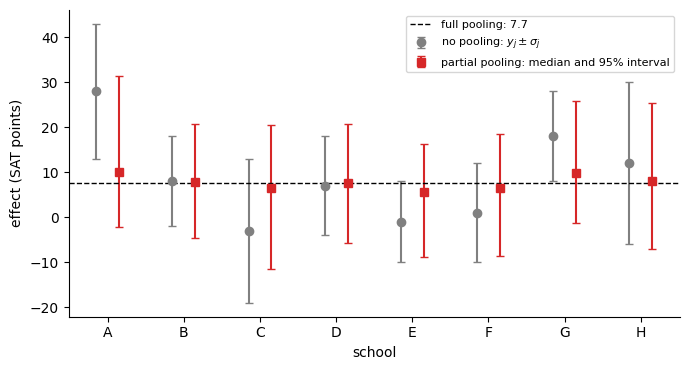

In [11]:
w8 = 1 / sig8**2
theta_full = np.sum(w8 * y8) / np.sum(w8)
se_full = np.sqrt(1 / np.sum(w8))
chi_stat = np.sum((y8 - theta_full) ** 2 * w8)
p_full = stats.chi2.sf(chi_stat, J - 1)
print(f"full pooling: estimate {theta_full:.1f}, standard error {se_full:.1f}")
print(f"chi-square for equal effects: {chi_stat:.1f} on {J - 1} df, p = {p_full:.2f}")

est = pd.DataFrame({"no pooling": y8, "partial pooling": qs.loc[names, "50%"].to_numpy(),
                    "full pooling": theta_full}, index=names)
print(est.round(1).to_string())

# Unequal-sigma shrinkage: weight on y_j at tau = posterior median
tau_med = np.median(tau_draws)
weight_y = tau_med**2 / (tau_med**2 + sig8**2)
print(f"\nweight on y_j at tau = {tau_med:.1f}: " + ", ".join(f"{n_}: {w_:.2f}" for n_, w_ in zip(names, weight_y)))

fig, ax = plt.subplots(figsize=(7, 3.8))
x_pos = np.arange(J)
ax.errorbar(x_pos - 0.15, y8, yerr=sig8, fmt="o", color="gray", capsize=3, label="no pooling: $y_j \\pm \\sigma_j$")
lo, hi = qs.loc[names, "2.5%"].to_numpy(), qs.loc[names, "97.5%"].to_numpy()
mid = qs.loc[names, "50%"].to_numpy()
ax.errorbar(x_pos + 0.15, mid, yerr=[mid - lo, hi - mid], fmt="s", color="C3", capsize=3, label="partial pooling: median and 95% interval")
ax.axhline(theta_full, color="black", ls="--", lw=1, label=f"full pooling: {theta_full:.1f}")
ax.set_xticks(x_pos)
ax.set_xticklabels(names)
ax.set_xlabel("school")
ax.set_ylabel("effect (SAT points)")
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

**Reading.**

- The full pooling estimate is 7.7 with standard error 4.1. The chi-square statistic is 4.7 on 7 degrees of freedom, with $p =$ 0.70. The test does not reject equal effects.
- Neither extreme is sensible alone. School A at 28 is hard to believe when its standard error is 15. Full pooling gives School A the same effect as School E, which throws away what School A reported.
- Partial pooling sits between them. In the plot, the red squares are pulled from the gray circles toward the dashed line. The schools with large $\sigma_j$ (A, C, and H) give their own $y_j$ the least weight.

**The shrinkage formula with unequal $\sigma_j$.** Given $\mu$ and $\tau$, the posterior mean of $\theta_j$ is

$$E[\theta_j \mid \mu, \tau, y] = (1 - B_j)\, y_j + B_j\, \mu, \qquad B_j = \frac{\sigma_j^2}{\sigma_j^2 + \tau^2}.$$

$B_j$ is the weight on the shared mean $\mu$. The weight on $y_j$ is $1 - B_j = \tau^2/(\tau^2 + \sigma_j^2)$. A school with a larger standard error $\sigma_j$ has a larger $B_j$ and moves further toward $\mu$. At $\tau =$ 5.2 the weight on $y_j$ is 0.11 for school A ($\sigma =$ 15) and 0.25 for school E ($\sigma =$ 9). Section 1 is the special case with one group and a fixed $\tau$.

**Slow mixing when $\tau$ is near zero.** The sampler moves slowly when $\tau$ is small. A small $\tau$ pulls the $\theta_j$ together. Then the sum $\sum_j(\theta_j - \mu)^2$ is small, and a small sum makes the next draw of $\tau$ small. The chain can stay near zero for a long time. The trace plot shows the first 2,000 draws of $\tau$ after the burn-in, and the autocorrelation of the whole chain.

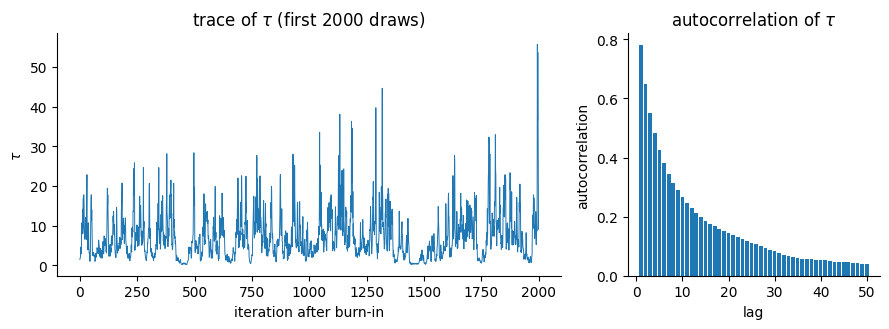

share of draws with tau < 1: 0.106; longest run of consecutive draws with tau < 1: 209
minimum tau in the chain: 0.000


In [12]:
run_len, longest, cur = 0, 0, 0
for t in tau_draws < 1.0:
    cur = cur + 1 if t else 0
    longest = max(longest, cur)
frac_small = np.mean(tau_draws < 1.0)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(tau_draws[:2000], lw=0.7)
axes[0].set_xlabel("iteration after burn-in")
axes[0].set_ylabel("$\\tau$")
axes[0].set_title("trace of $\\tau$ (first 2000 draws)")
lags = np.arange(1, 51)
axes[1].bar(lags, [acf(tau_draws, k) for k in lags], color="C0")
axes[1].set_xlabel("lag")
axes[1].set_ylabel("autocorrelation")
axes[1].set_title("autocorrelation of $\\tau$")
plt.tight_layout()
plt.show()
print(f"share of draws with tau < 1: {frac_small:.3f}; longest run of consecutive draws with tau < 1: {longest}")
print(f"minimum tau in the chain: {tau_draws.min():.3f}")

**Reading.**

- In the trace, $\tau$ moves in slow waves. It drops close to zero, stays there for a stretch, and then climbs back up. It does not jump around freely. The autocorrelation bars decay slowly.
- A share of 0.106 of the draws have $\tau < 1$. The longest run of consecutive draws below 1 is 209 draws.
- This slow mixing is why the chain has 200,000 steps. Section 7 uses a different way to write the model, so that the sampler does not get stuck there.

**Try it on your project.** Put a flat or weak prior on $\tau$ and learn it. Report the posterior median and interval of $\tau$, and the group estimates for no, partial, and full pooling. Plot the trace of $\tau$. If it sticks near zero, run a longer chain or use the non-centered form in Section 7.

## 6. Bayesian linear regression and an upper quantile

**Idea.** For a regression with a conjugate prior, the posterior and the predictive have closed forms. The predictive is a Student t. It is wider than the plug-in least squares interval, and the width grows as you move away from the data.

**Data.** Real data from the course folder: `SaratogaHouses.csv`, home sales with price and size. We take a random subset of 40 houses. The outcome is $y = \log(\text{price})$. The predictor is the living area in thousands of square feet, centered at the subset mean. We also center $y$. The 40 houses are a subset, so the intervals below are wide on purpose.

**Notation.** $X$ is the $n \times 2$ design matrix (a column of ones and the centered area). $\beta$ is the vector of two coefficients. $\sigma^2$ is the noise variance.

**Prior.** $\beta \mid \sigma^2 \sim N(m_0, \sigma^2 \Lambda_0^{-1})$ and $\sigma^2 \sim \text{Inv-Gamma}(a_0, b_0)$. We use $m_0 = 0$, $\Lambda_0 = 0.01\, I$ and $a_0 = b_0 = 0.01$, which is very weak.

**Posterior.**

$$\Lambda_n = \Lambda_0 + X^\top X, \quad m_n = \Lambda_n^{-1}(\Lambda_0 m_0 + X^\top y), \quad a_n = a_0 + \tfrac{n}{2}, \quad b_n = b_0 + \tfrac12\left(y^\top y + m_0^\top \Lambda_0 m_0 - m_n^\top \Lambda_n m_n\right).$$

**Predictive.** For a new row $x_*$, the posterior predictive of the new outcome is Student t with $2a_n$ degrees of freedom, location $x_*^\top m_n$ and scale$^2$ $= (b_n/a_n)\left(1 + x_*^\top \Lambda_n^{-1} x_*\right)$. The term $x_*^\top \Lambda_n^{-1} x_*$ grows when $x_*$ is far from the data.

**Plug-in least squares.** The plug-in interval takes the fitted line and adds a normal band $\pm z\, s$, where $s$ is the residual standard deviation. It ignores the doubt about the line.

subset: 40 houses; living area from 0.91 to 3.34 thousand sq ft (mean 1.81)
posterior mean slope 0.473 (least squares 0.473); residual sd s = 0.532; t degrees of freedom 40

80% predictive interval width in log price (upper minus lower)
  at the mean area                     Bayes 1.369   plug-in 1.363
  at the largest area in the subset    Bayes 1.454   plug-in 1.363
  2000 sq ft above the largest         Bayes 1.773   plug-in 1.363

critical ratio gamma = 0.90 (made-up costs 9 and 1)
  a house of 1800 sq ft                  Bayes cap $  347,287   plug-in cap $  346,307
  a house 2000 sq ft above the largest   Bayes cap $2,270,153   plug-in cap $1,851,414


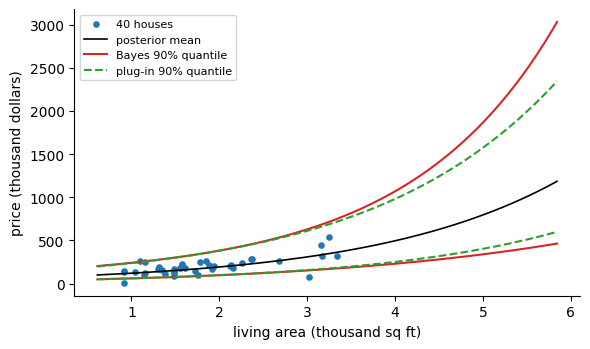

In [13]:
sar = pd.read_csv(DATA / "SaratogaHouses.csv", index_col=0)
sub = sar.sample(40, random_state=6)
area = sub.livingArea.to_numpy() / 1000.0
log_p = np.log(sub.price.to_numpy())
a_mean, p_mean = area.mean(), log_p.mean()
xc, yc = area - a_mean, log_p - p_mean
X = np.column_stack([np.ones(len(xc)), xc])
n6 = len(xc)

m0 = np.zeros(2)
Lam0 = 0.01 * np.eye(2)
a0_, b0_ = 0.01, 0.01
Lam_n = Lam0 + X.T @ X
m_n = np.linalg.solve(Lam_n, Lam0 @ m0 + X.T @ yc)
a_n6 = a0_ + n6 / 2
b_n6 = b0_ + 0.5 * (yc @ yc + m0 @ Lam0 @ m0 - m_n @ Lam_n @ m_n)
Lam_inv = np.linalg.inv(Lam_n)

beta_ols = np.linalg.lstsq(X, yc, rcond=None)[0]
resid = yc - X @ beta_ols
s_ols = np.sqrt(resid @ resid / (n6 - 2))

def band(x_new, level):
    """Return (centre, half-width) in log price for the Bayes Student t and the plug-in normal."""
    xs = np.array([1.0, x_new])
    centre = xs @ m_n
    scale = np.sqrt(b_n6 / a_n6 * (1 + xs @ Lam_inv @ xs))
    half_bayes = stats.t.ppf(level, 2 * a_n6) * scale
    half_plug = stats.norm.ppf(level) * s_ols
    return centre, half_bayes, half_plug, xs @ beta_ols

print(f"subset: {n6} houses; living area from {area.min():.2f} to {area.max():.2f} thousand sq ft (mean {a_mean:.2f})")
print(f"posterior mean slope {m_n[1]:.3f} (least squares {beta_ols[1]:.3f}); residual sd s = {s_ols:.3f}; t degrees of freedom {2 * a_n6:.0f}")

# width of the 80% predictive interval at three places
places = {"at the mean area": 0.0,
          "at the largest area in the subset": area.max() - a_mean,
          "2000 sq ft above the largest": area.max() + 2.0 - a_mean}
print("\n80% predictive interval width in log price (upper minus lower)")
for label, x_new in places.items():
    _, hb, hp, _ = band(x_new, 0.90)
    print(f"  {label:36s} Bayes {2 * hb:.3f}   plug-in {2 * hp:.3f}")

# decision: quote an upper price with critical ratio 0.9 (costs are made up)
c_under6, c_over6 = 9.0, 1.0
gamma6 = c_under6 / (c_under6 + c_over6)
print(f"\ncritical ratio gamma = {gamma6:.2f} (made-up costs {c_under6:.0f} and {c_over6:.0f})")
caps = {}
for label, x_new in (("a house of 1800 sq ft", 1.8 - a_mean), ("a house 2000 sq ft above the largest", area.max() + 2.0 - a_mean)):
    centre, hb, hp, ols_centre = band(x_new, gamma6)
    caps[label] = (np.exp(centre + hb + p_mean), np.exp(ols_centre + hp + p_mean))
    print(f"  {label:38s} Bayes cap ${caps[label][0]:>9,.0f}   plug-in cap ${caps[label][1]:>9,.0f}")

xx = np.linspace(area.min() - 0.3, area.max() + 2.5, 200)
res = np.array([band(x - a_mean, 0.90) for x in xx])
plt.figure()
plt.scatter(area, np.exp(log_p) / 1000, color="C0", s=14, label="40 houses")
plt.plot(xx, np.exp(res[:, 0] + p_mean) / 1000, color="black", lw=1.2, label="posterior mean")
plt.plot(xx, np.exp(res[:, 0] + res[:, 1] + p_mean) / 1000, color="C3", lw=1.5, label="Bayes 90% quantile")
plt.plot(xx, np.exp(res[:, 0] - res[:, 1] + p_mean) / 1000, color="C3", lw=1.5)
plt.plot(xx, np.exp(res[:, 3] + res[:, 2] + p_mean) / 1000, color="C2", ls="--", lw=1.5, label="plug-in 90% quantile")
plt.plot(xx, np.exp(res[:, 3] - res[:, 2] + p_mean) / 1000, color="C2", ls="--", lw=1.5)
plt.xlabel("living area (thousand sq ft)")
plt.ylabel("price (thousand dollars)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Reading.**

- The posterior mean slope is 0.473 log-price units per thousand square feet. Least squares gives 0.473. The prior is so weak that the two almost agree.
- The predictive has 40 degrees of freedom, about $n$. With 40 houses a Student t is a little wider than a normal.
- At the mean area, the 80% interval is 1.369 wide for the Bayes predictive and 1.363 for the plug-in. The Bayes interval is slightly wider even at the center.
- Two thousand square feet above the largest house in the subset, the Bayes interval is 1.773 wide. The plug-in stays at 1.363. The Bayes interval widens away from the data, and the plug-in one does not.
- With the costs given, $\gamma =$ 0.90, so we quote the 90% quantile. For a 1800 square foot house the cap is \$347,287 from the Bayes predictive and \$346,307 from the plug-in. For the far house the caps are \$2,270,153 and \$1,851,414. The plug-in cap is too low when you extrapolate.
- The quantile of the price is the exponential of the quantile of log price, because the exponential is increasing.

With a nearly flat prior, the Student t predictive is the same as the textbook least squares prediction interval. The plug-in interval is the shortcut that leaves out the doubt about $\beta$.

**Try it on your project.** Write down the prior on $\beta$ and say why it is weak or strong. Compute the Student t predictive at the rows you will decide on, and take the $\gamma$ quantile. Plot the band over the range of your predictor and past its edge. Treat any decision outside the range of the data with extra care.

## 7. A hierarchical logistic model, and a plain Bayesian logistic

**Idea.** For a binary outcome with many groups and few trials each, let each group have its own intercept drawn from a shared distribution. Fit it by NUTS (a Hamiltonian Monte Carlo sampler) in `numpyro`.

**Data.** **Simulated**, labeled as such. There are 30 groups with 4 to 12 training trials each. Each trial has one covariate $x$. The truth is

$$P(y = 1) = \text{logistic}(\alpha_g + \beta x), \qquad \alpha_g \sim N(\mu, \sigma_\alpha^2).$$

Here $\alpha_g$ is the intercept of group $g$, $\mu = -0.4$ is the average intercept, $\sigma_\alpha = 1.0$ is its spread across groups, and the common slope is $\beta = 1.0$. Each group also has 100 held-out trials, which we use for scoring.

**Model.** $\alpha_g = \mu + \sigma_\alpha z_g$ with $z_g \sim N(0, 1)$. This is the non-centered form. Priors: $\mu \sim N(0, 2^2)$, $\sigma_\alpha \sim \text{Half-Normal}(1.5)$, $\beta \sim N(0, 2^2)$.

**Why non-centered.** In Section 5 the sampler moved slowly when $\tau$ was near zero because $\tau$ and the group effects pulled each other. Writing $\alpha_g = \mu + \sigma_\alpha z_g$ with independent standard normal $z_g$ removes that pull.

**Three models.** We compare them on held-out log loss. Log loss is $-\frac{1}{N}\sum_i \log P(\text{observed } y_i)$, and lower is better.

- *Separate*: one logistic regression per group. A group with only one class in its training data gets the training frequency as a constant.
- *Pooled*: one logistic regression on all rows that ignores the group.
- *Hierarchical*: the model above. Its predictive probability is the average over the posterior draws.

All predicted probabilities are clipped to between 0.001 and 0.999.

In [14]:
import jax
from numpyro.diagnostics import summary
from numpyro.infer import MCMC, NUTS
import numpyro.distributions as dist
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

rng = np.random.default_rng(11)
G = 30
mu_true, sd_true, beta_true = -0.4, 1.0, 1.0
alpha_true = rng.normal(mu_true, sd_true, G)
n_tr = rng.integers(4, 13, G)
g_tr = np.repeat(np.arange(G), n_tr)
x_tr = rng.normal(size=g_tr.size)
y_tr = rng.binomial(1, expit(alpha_true[g_tr] + beta_true * x_tr))
g_te = np.repeat(np.arange(G), 100)
x_te = rng.normal(size=g_te.size)
y_te = rng.binomial(1, expit(alpha_true[g_te] + beta_true * x_te))

def clip(p):
    return np.clip(p, 1e-3, 1 - 1e-3)

# separate logistic per group (small penalty, C = 100, so the fit exists)
p_sep = np.empty(len(y_te))
n_single = 0
for g in range(G):
    tr, te = g_tr == g, g_te == g
    if len(np.unique(y_tr[tr])) < 2:
        p_sep[te] = y_tr[tr].mean()
        n_single += 1
    else:
        p_sep[te] = LogisticRegression(C=100).fit(x_tr[tr, None], y_tr[tr]).predict_proba(x_te[te, None])[:, 1]

# one pooled logistic
p_pool = LogisticRegression(C=1e6).fit(x_tr[:, None], y_tr).predict_proba(x_te[:, None])[:, 1]

# hierarchical, non-centered, NUTS
def hier(g, x, y=None):
    mu = numpyro.sample("mu", dist.Normal(0.0, 2.0))
    s_a = numpyro.sample("s_a", dist.HalfNormal(1.5))
    beta = numpyro.sample("beta", dist.Normal(0.0, 2.0))
    with numpyro.plate("groups", G):
        z = numpyro.sample("z", dist.Normal(0.0, 1.0))
    alpha = mu + s_a * z
    numpyro.sample("y", dist.Bernoulli(logits=alpha[g] + beta * x), obs=y)

mcmc = MCMC(NUTS(hier), num_warmup=500, num_samples=1000, num_chains=4, chain_method="sequential", progress_bar=False)
mcmc.run(jax.random.PRNGKey(0), g_tr, x_tr, y_tr, extra_fields=("diverging",))
smp = mcmc.get_samples()
n_div = int(mcmc.get_extra_fields()["diverging"].sum())
rhat_max = max(float(np.max(v["r_hat"])) for v in summary(mcmc.get_samples(group_by_chain=True)).values())

alpha_s = np.array(smp["mu"])[:, None] + np.array(smp["s_a"])[:, None] * np.array(smp["z"])
logit_te = alpha_s[:, g_te] + np.array(smp["beta"])[:, None] * x_te[None, :]
p_hier = expit(logit_te).mean(axis=0)               # average over draws

ll = {name: log_loss(y_te, clip(p)) for name, p in (("separate", p_sep), ("pooled", p_pool), ("hierarchical", p_hier))}
s_q = np.quantile(np.array(smp["s_a"]), [0.05, 0.5, 0.95])
print(f"simulated: {G} groups, {len(y_tr)} training trials, {len(y_te)} held-out trials; groups with one class only: {n_single}")
print(f"NUTS: divergences {n_div}, largest r_hat {rhat_max:.3f}")
print(f"spread of group intercepts: true {sd_true:.1f}; posterior median {s_q[1]:.2f} (90% interval {s_q[0]:.2f} to {s_q[2]:.2f})")
print("held-out log loss (lower is better)")
for name, v in ll.items():
    print(f"  {name:13s} {v:.3f}")

simulated: 30 groups, 233 training trials, 3000 held-out trials; groups with one class only: 4
NUTS: divergences 0, largest r_hat 1.002
spread of group intercepts: true 1.0; posterior median 1.15 (90% interval 0.76 to 1.68)
held-out log loss (lower is better)
  separate      1.129
  pooled        0.604
  hierarchical  0.576


**Reading.**

- The sampler had 0 divergences, and the largest $\hat R$ is 1.002. A value close to 1 and no divergences mean the chains agree.
- The posterior median of $\sigma_\alpha$ is 1.15, with a 90% interval from 0.76 to 1.68. The true value in the simulation is 1.0.
- Held-out log loss is 1.129 for separate fits, 0.604 for the pooled fit, and 0.576 for the hierarchical model. The hierarchical model is best.
- Separate fits have too little data per group. In 4 groups the training data had only one class, so the fit could only repeat that class. The pooled fit ignores real differences between groups.

**A plain Bayesian logistic with a weakly informative prior.** For one population with no groups, put a prior on the coefficients and sample. A weakly informative choice is $N(0, 2.5^2)$ on each coefficient of a standardized covariate. The predictive probability for a new row is the average of $\text{logistic}(x_*^\top \beta^{(s)})$ over the posterior draws $\beta^{(s)}$, not the logistic of the average $\beta$.

**Decision cutoff.** Flag a row when the cost of not flagging, in expectation, exceeds the cost of flagging. Let $c_{\text{miss}}$ be the cost of missing a positive and $c_{\text{fa}}$ the cost of a false alarm, with ratio $r = c_{\text{miss}}/c_{\text{fa}}$. Flag when $p\, c_{\text{miss}} > (1 - p)\, c_{\text{fa}}$, which is $p > 1/(1 + r)$.

The next code uses **simulated** data with $n = 80$ training rows and two covariates, with true coefficients $(-0.5, 1.2, -0.8)$. The costs are made up: $r = 4$.

In [15]:
rng = np.random.default_rng(21)
beta_t = np.array([-0.5, 1.2, -0.8])          # simulated truth: intercept and two slopes
def make(n):
    Z = rng.normal(size=(n, 2))
    return Z, rng.binomial(1, expit(beta_t[0] + Z @ beta_t[1:]))
Z_tr, yb_tr = make(80)
Z_te, yb_te = make(4000)

def logit_model(Z, yb=None):
    b0 = numpyro.sample("b0", dist.Normal(0.0, 5.0))
    b = numpyro.sample("b", dist.Normal(0.0, 2.5).expand([2]).to_event(1))
    numpyro.sample("y", dist.Bernoulli(logits=b0 + Z @ b), obs=yb)

m2 = MCMC(NUTS(logit_model), num_warmup=500, num_samples=1000, num_chains=4, chain_method="sequential", progress_bar=False)
m2.run(jax.random.PRNGKey(1), Z_tr, yb_tr)
s2 = m2.get_samples()
b0s, bs = np.array(s2["b0"]), np.array(s2["b"])

p_avg = expit(b0s[:, None] + bs @ Z_te.T).mean(axis=0)                    # average over draws
p_plug = expit(b0s.mean() + Z_te @ bs.mean(axis=0))                        # plug in the posterior mean
row = np.array([[2.5, -2.5]])
p_row_avg = expit(b0s + bs @ row.T[:, 0]).mean()
p_row_plug = expit(b0s.mean() + row @ bs.mean(axis=0))[0]

r_cost = 4.0                                   # made-up: a miss costs 4, a false alarm costs 1
cut = 1 / (1 + r_cost)
def total_cost(p, cutoff):
    flag = p > cutoff
    return np.mean(np.where(flag, (1 - yb_te) * 1.0, yb_te * r_cost))
draws_all = np.column_stack([b0s, bs])
ci = np.quantile(draws_all, [0.05, 0.95], axis=0)
covered = int(np.sum((ci[0] <= beta_t) & (beta_t <= ci[1])))
print(f"posterior mean coefficients: {b0s.mean():.2f}, {bs.mean(axis=0)[0]:.2f}, {bs.mean(axis=0)[1]:.2f}   (truth {beta_t.tolist()})")
print("90% intervals: " + "; ".join(f"({lo:.2f}, {hi:.2f})" for lo, hi in ci.T) + f"; {covered} of 3 contain the truth")
print(f"test log loss: averaged over draws {log_loss(yb_te, clip(p_avg)):.4f}, plug-in {log_loss(yb_te, clip(p_plug)):.4f}")
print(f"extreme row (2.5, -2.5): averaged {p_row_avg:.3f}, plug-in {p_row_plug:.3f}, true {expit(beta_t[0] + row @ beta_t[1:])[0]:.3f}")
print(f"r = {r_cost:.0f}, cutoff 1/(1+r) = {cut:.2f}")
print(f"cost per row on 4000 test rows: cutoff 0.5 -> {total_cost(p_avg, 0.5):.3f}; cutoff {cut:.2f} -> {total_cost(p_avg, cut):.3f}")

# when the prior matters: MAP fits (equivalent to ridge with C = prior variance) at small and large n
rows_prior = []
for n_ in (80, 8000):
    Zs, ys = (Z_tr, yb_tr) if n_ == 80 else make(n_)
    fit_sd = lambda sd: LogisticRegression(C=sd**2, max_iter=1000).fit(Zs, ys).coef_[0][0]
    rows_prior.append((n_, fit_sd(0.5), fit_sd(2.5)))
print("\nMAP slope of the first covariate under a tight prior (sd 0.5) and a weak prior (sd 2.5); truth 1.2")
print("(n = 80 is the training set above; n = 8000 is a new simulated set)")
for n_, tight, weak in rows_prior:
    print(f"  n = {n_:5d}   tight {tight:.3f}   weak {weak:.3f}   difference {abs(tight - weak):.3f}")

posterior mean coefficients: -0.26, 1.78, -1.22   (truth [-0.5, 1.2, -0.8])
90% intervals: (-0.74, 0.20); (1.14, 2.52); (-1.84, -0.66); 3 of 3 contain the truth
test log loss: averaged over draws 0.5433, plug-in 0.5506
extreme row (2.5, -2.5): averaged 0.998, plug-in 0.999, true 0.989
r = 4, cutoff 1/(1+r) = 0.20
cost per row on 4000 test rows: cutoff 0.5 -> 0.615; cutoff 0.20 -> 0.465

MAP slope of the first covariate under a tight prior (sd 0.5) and a weak prior (sd 2.5); truth 1.2
(n = 80 is the training set above; n = 8000 is a new simulated set)
  n =    80   tight 1.042   weak 1.653   difference 0.611
  n =  8000   tight 1.137   weak 1.142   difference 0.005


**Reading.**

- With only 80 rows the posterior means are noisy. The intercept and slopes are -0.26, 1.78, and -1.22, against the simulated truth $(-0.5, 1.2, -0.8)$. Their 90% intervals contain the truth for 3 of the 3 coefficients. The intervals are wide, and that width is the honest answer at this $n$.
- On 4000 test rows the log loss is 0.5433 when we average over draws and 0.5506 when we plug in the posterior mean. Averaging is a little better.
- For a row far from the data, $(2.5, -2.5)$, averaging over draws gives 0.998 and plugging in the posterior mean gives 0.999. The true probability is 0.989. Averaging can only pull toward 0.5. Here it pulls very little, because nearly every draw puts this row far out on the same side. Both numbers are above the truth because the fitted slopes at $n = 80$ are too large.
- With $r = 4$ the cutoff is $1/(1+r) =$ 0.20, not 0.5. On 4000 test rows the cost per row is 0.615 at the 0.5 cutoff and 0.465 at the cost-based cutoff.
- **When the prior barely matters:** when $n$ is large. At $n = 80$ the tight prior (sd 0.5) and the weak prior (sd 2.5) differ in the slope by 0.611. At $n = 8000$ they differ by 0.005. With few trials per group, as in the hierarchical model above, the prior does matter.

**An alternative.** A gradient boosted classifier (GBC) also outputs a probability and handles interactions with no model to write down. It does not give a posterior or a shared prior over groups. See [quantiles-gbc.ipynb](quantiles-gbc.ipynb).

**Try it on your project.** Write the model in the non-centered form. Report the divergence count and $\hat R$. Compare against a separate fit per group and a pooled fit on held-out log loss, where held-out means whole groups or later times, as in Section 9. Set the cutoff from your own cost ratio, not from 0.5.

## 8. The value of more data

**Idea.** Before you collect another measurement, compute what it is expected to be worth, and compare that with its cost.

**Setup.** All numbers in this section are **simulated or made up**. A stored baseline says that replacing a part with a new one changes the outcome by $\theta$ (the gain, in outcome units). We believe $\theta \sim N(m_0, s_0^2)$ from the baseline. A probe is a noisy measurement $y = \theta + e$ with $e \sim N(0, s_e^2)$.

**Actions and losses.** The costs and the loss for each action:

- *Keep* the baseline. We lose $(\theta - c_r)^+$ if replacing would have been better. Here $c_r$ is the fixed cost of replacing, and $(u)^+ = \max(u, 0)$.
- *Replace*. We lose $(c_r - \theta)^+$ if keeping would have been better.
- *Buy $k$ probes*, then choose the cheaper action. This costs $k\, c_p$ for the probes, with $c_p$ the cost per probe.

For a normal $\theta \sim N(m, s^2)$, the expected loss of keeping is $E(\theta - c_r)^+ = s\,\varphi(d) + (m - c_r)\Phi(d)$ with $d = (m - c_r)/s$. Here $\varphi$ and $\Phi$ are the standard normal density and cdf. The expected loss of replacing is the same expression minus $(m - c_r)$.

**Preposterior calculation.** The probes have not been observed yet. After $k$ probes with average $\bar y_k$, the posterior of $\theta$ has variance $s_k^2 = (1/s_0^2 + k/s_e^2)^{-1}$ and a mean $m_k$. Before we see the probes, $m_k$ is itself random with a normal distribution, with mean $m_0$ and variance $s_0^2 - s_k^2$. The expected loss with $k$ probes averages the better action's posterior loss over what the probes could say:

$$L_k = E_{m_k}\left[\min\left(\text{loss}_{\text{keep}}(m_k, s_k),\; \text{loss}_{\text{replace}}(m_k, s_k)\right)\right] + k\, c_p.$$

We compute the average by quadrature and check it by simulation.

now: expected loss of keeping 0.573, of replacing 1.073; best action: keep
probes  expected loss  value of information  probe cost  total
   0       0.573            0.000            0.00      0.573
   1       0.336            0.237            0.15      0.486
   2       0.237            0.336            0.30      0.537
   3       0.184            0.389            0.45      0.634
   4       0.151            0.422            0.60      0.751
   5       0.128            0.445            0.75      0.878
   6       0.111            0.462            0.90      1.011
   7       0.098            0.475            1.05      1.148
   8       0.088            0.485            1.20      1.288
   9       0.080            0.493            1.35      1.430
  10       0.073            0.500            1.50      1.573
best number of probes: 1
check for k = 3: quadrature 0.184, simulation 0.187


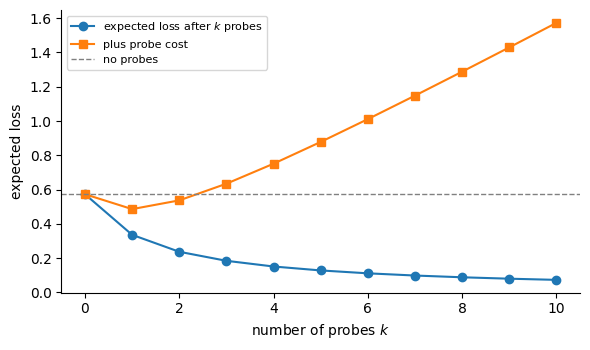

In [16]:
m0_, s0_ = 0.5, 2.0       # made-up baseline belief about the gain
c_r = 1.0                 # made-up cost of replacing
s_e = 3.0                 # made-up probe noise sd
c_p = 0.15                # made-up cost per probe

def loss_keep(m, s):
    d = (m - c_r) / s
    return s * stats.norm.pdf(d) + (m - c_r) * stats.norm.cdf(d)

def loss_replace(m, s):
    return loss_keep(m, s) - (m - c_r)

def expected_loss(k):
    if k == 0:
        return min(loss_keep(m0_, s0_), loss_replace(m0_, s0_))
    s_k = (1 / s0_**2 + k / s_e**2) ** -0.5
    sd_m = np.sqrt(s0_**2 - s_k**2)
    z, wq = np.polynomial.hermite_e.hermegauss(80)
    wq = wq / wq.sum()
    m_k = m0_ + sd_m * z
    return np.sum(wq * np.minimum(loss_keep(m_k, s_k), loss_replace(m_k, s_k)))

ks = np.arange(0, 11)
exp_l = np.array([expected_loss(k) for k in ks])
total = exp_l + c_p * ks
k_star8 = int(ks[total.argmin()])
voi = exp_l[0] - exp_l            # value of information of k probes, before paying for them

# simulation check for k = 3
rng = np.random.default_rng(8)
k_chk = 3
theta = rng.normal(m0_, s0_, 400_000)
ybar_k = theta + rng.normal(0, s_e / np.sqrt(k_chk), theta.size)
s_k = (1 / s0_**2 + k_chk / s_e**2) ** -0.5
m_post = s_k**2 * (m0_ / s0_**2 + ybar_k * k_chk / s_e**2)
keep_chosen = loss_keep(m_post, s_k) <= loss_replace(m_post, s_k)
realized = np.where(keep_chosen, np.maximum(theta - c_r, 0), np.maximum(c_r - theta, 0)).mean()

print(f"now: expected loss of keeping {loss_keep(m0_, s0_):.3f}, of replacing {loss_replace(m0_, s0_):.3f}; best action: {'keep' if loss_keep(m0_, s0_) < loss_replace(m0_, s0_) else 'replace'}")
print("probes  expected loss  value of information  probe cost  total")
for k in ks:
    print(f"  {k:2d}       {exp_l[k]:.3f}            {voi[k]:.3f}            {c_p * k:.2f}      {total[k]:.3f}")
print(f"best number of probes: {k_star8}")
print(f"check for k = {k_chk}: quadrature {exp_l[k_chk]:.3f}, simulation {realized:.3f}")

plt.figure()
plt.plot(ks, exp_l, "o-", label="expected loss after $k$ probes")
plt.plot(ks, total, "s-", label="plus probe cost")
plt.axhline(exp_l[0], color="gray", ls="--", lw=1, label="no probes")
plt.xlabel("number of probes $k$")
plt.ylabel("expected loss")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Reading.**

- With no probes, keeping has an expected loss of 0.573 and replacing has 1.073. The baseline mean gain of 0.5 is below the replacement cost of 1.0, so keeping is the better action now, but its loss is not small, because $\theta$ is uncertain.
- One probe is worth 0.237 in loss reduction and costs 0.15. Three probes are worth 0.389 and cost 0.45.
- The total (expected loss plus probe cost) is smallest at $k =$ 1, with a value of 0.486. The total with no probes is 0.573. Probes beyond $k =$ 1 cost more than they save.
- The simulation for three probes gives 0.187 against 0.184 from the calculation. They agree.
- Each extra probe is worth less than the one before it. The first measurement removes the most doubt. A baseline with a small $s_0$ is worth less to probe, and a noisy probe with a large $s_e$ is also worth less. Change `s0_` and `s_e` in the code to see this.

This is the same logic as the value of a test section in Lab 8. There, a test result updates a belief and changes the best action. Here the test is a measurement and the belief is a normal prior.

**Try it on your project.** State the baseline as a prior, the probe noise, the cost of acting, and the cost per probe. Compute the expected loss now, with one more measurement, and with several. If the best $k$ is zero, buying the measurement does not pay.

## 9. Scoring: hold out whole groups

**Idea.** If new groups will arrive (new people, new hulls, new lifters), the test set must contain groups the model never saw. A random split of rows puts rows from the same group in both training and test, and a model that learns each group's level looks better than it is.

**Simulated case.** The data here are **simulated**. There are 40 groups with 25 rows each. For row $i$ in group $g$, $y = 2 + x + u_g + \varepsilon$. The $x$ is a standard normal covariate, $u_g \sim N(0, 1.5^2)$ is a group effect, and $\varepsilon \sim N(0, 1)$ is noise. Two models:

- *x only*: ridge regression on $x$.
- *x plus group*: ridge regression on $x$ and one dummy per group. It learns each group's level.

We score by the root mean squared error (RMSE) under two splits. `KFold` splits rows at random. `GroupKFold` keeps each group entirely in train or entirely in test.

RMSE by model and split
  x only        row-wise  1.868
  x only        by group  1.904
  x plus group  row-wise  1.026
  x plus group  by group  1.899
best possible RMSE on a new group with no group information: sqrt(1.5^2 + 1) = 1.803

coverage of the nominal 80% interval built from the row-wise RMSE 1.03:
  on row-wise folds 0.79; on held-out groups 0.50


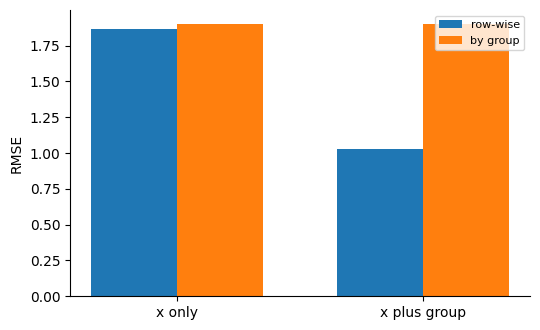

In [17]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict

rng = np.random.default_rng(9)
n_groups, per = 40, 25
grp = np.repeat(np.arange(n_groups), per)
u = rng.normal(0, 1.5, n_groups)
x9 = rng.normal(size=grp.size)
y9 = 2 + x9 + u[grp] + rng.normal(size=grp.size)

X_x = x9[:, None]
X_xg = np.column_stack([x9, np.eye(n_groups)[grp]])

def rmse_and_err(X, splitter, **kw):
    pred = cross_val_predict(Ridge(alpha=1.0), X, y9, cv=splitter, **kw)
    err = y9 - pred
    return np.sqrt(np.mean(err**2)), err

kf = KFold(5, shuffle=True, random_state=0)
gkf = GroupKFold(5)
res9 = {}
for model, X in (("x only", X_x), ("x plus group", X_xg)):
    res9[(model, "row-wise")] = rmse_and_err(X, kf)
    res9[(model, "by group")] = rmse_and_err(X, gkf, groups=grp)
print("RMSE by model and split")
for (model, split), (r, _) in res9.items():
    print(f"  {model:13s} {split:9s} {r:.3f}")
floor = np.sqrt(1.5**2 + 1)
print(f"best possible RMSE on a new group with no group information: sqrt(1.5^2 + 1) = {floor:.3f}")

# calibration: intervals built from row-wise errors, used on new groups
z80 = stats.norm.ppf(0.9)
sd_row = res9[("x plus group", "row-wise")][0]
cov_row = np.mean(np.abs(res9[("x plus group", "row-wise")][1]) < z80 * sd_row)
cov_new = np.mean(np.abs(res9[("x plus group", "by group")][1]) < z80 * sd_row)
print(f"\ncoverage of the nominal 80% interval built from the row-wise RMSE {sd_row:.2f}:")
print(f"  on row-wise folds {cov_row:.2f}; on held-out groups {cov_new:.2f}")

fig, ax = plt.subplots(figsize=(5.5, 3.4))
wd = 0.35
for j, split in enumerate(("row-wise", "by group")):
    ax.bar(np.arange(2) + (j - 0.5) * wd, [res9[(m, split)][0] for m in ("x only", "x plus group")], wd, label=split)
ax.set_xticks(np.arange(2))
ax.set_xticklabels(["x only", "x plus group"])
ax.set_ylabel("RMSE")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Reading.**

- Under the row-wise split, the group model has an RMSE of 1.026, against 1.868 for the model with $x$ only. It looks far better, because the group dummies see the same groups in training and test.
- Under the group split, the group model has an RMSE of 1.899 and the $x$-only model has 1.904. The advantage is gone. On a new group there is no dummy to learn, and the best possible RMSE is about 1.803.
- The row-wise score would have told you to expect an error near 1.03 on new groups. The real error is 1.90.
- An interval built from the row-wise error nominally covers 80%. It covers 79% on the row-wise folds and only 50% on held-out groups.

The correct split uses `GroupKFold(n_splits)` and passes `groups=` to `cross_val_predict` or `cross_val_score`, as above. The same rule applies to time: if you will predict the future, hold out the last periods, not random rows.

**Checklist before you report a result.**

1. **Prior stated.** Write down the prior in one sentence and say where it came from.
2. **$\tau$ inspected.** Look at the posterior of the spread parameter, its interval, and its trace or $\hat R$. Do not report a single value without its uncertainty.
3. **Predictive calibrated.** Check on held-out groups that an 80% predictive interval covers about 80%.
4. **Decision scored in its cost.** Score the final decision with the actual cost ratio, on held-out groups, against the simple baseline you started with.

**Try it on your project.** Find the unit that will be new at deployment (a person, a hull, a lifter). Split by that unit. Report the score from that split. Run the four checks above and write one line for each.